# 5.1 - Choosing a learning algorithm without hindsight

Notebook 3.4 replaced the formula value score with a model learned from accounting ratios, following Damon Lee's
*Build Your Own AI Investor* (2nd edition, 2021). It took the book's final model - gradient-boosted trees - as given.
The book reached that model by trying eight learning algorithms and keeping the one whose backtests looked best. This
notebook asks whether that choice survives being made the way an investor would have had to make it: with only the
past in hand.

It does three things:

1. **Explains the eight algorithms** - what each assumes, the formula it fits, what its settings do, and how
   differently they draw a prediction through the same data.
2. **Describes how the book chose among them**, step by step, and why each step overstates how well the winner works.
3. **Chooses again under a protocol fixed in advance**: the candidates, their settings, the yardstick and the rule
   for choosing are written down before any result is seen; each model is trained walk-forward; the choice itself is
   made walk-forward, each January from the evidence available that day; and every portfolio looked at is registered,
   so the deflated Sharpe ratio counts all of them.

## How the book chooses

Lee's data are about 15,600 company-years (2009-2020) of 18 accounting ratios, each paired with the share's price
change over the following year. His selection runs in five stages, every one of them judged on random splits of
those same company-years:

| Stage | Chapter | What is done | Outcome |
|---|---|---|---|
| Tune each model | 4 | validation curves of mean squared error, and the average *actual* return of the 10 stocks with the highest predicted return, over 10 random 90/10 train/test splits; grids over k (4-100), tree depth (2-50; 4-20 for forests) and the SVR's kernel, C, gamma and epsilon (a grid that "took a whole day") | k = 40; tree depth 20 (chapter 6's code; the text says 15); forest depth 10; SVR rbf, C = 100, gamma = 0.1, epsilon = 0.1 |
| Screen | 4 | the eight tuned models compared by their top-10 portfolios | extra trees dropped (top-10 return -0.6 % against 40 % for the random forest) |
| Fix the split | 6 | one backtest per model at each of seven test sizes | a 50/50 split |
| Backtest | 6 | for each of the seven survivors, many backtests of 2010-2020, each on a fresh random 50/50 split: each year the 7 test-half companies with the highest predicted return (and Altman Z'' above 2), equal weights, held a year | distributions of the final value of \$1 and of volatility, against the S&P 500 (\$3.51) |
| Choose | 6-7 | the best average outcomes: k-nearest neighbours \$3.94, gradient boosting \$3.95 | **gradient boosting**, because k-nearest neighbours was "a lot more volatile for little extra gain" - a judgement, as the book says |

(Chapter 7 opens by saying the random forest and k-nearest neighbours were the best; its code and its final choice
use gradient boosting and k-nearest neighbours, as chapter 6 concluded.)

Each stage overstates how well the winner will work, for three separate reasons:

* **Look-ahead bias, in the fit and in the choice.** A random split of company-years puts 2018 in the training half
  and 2015 in the test half, so the model "predicts" 2015 having learned from 2018 - and the market of 2018 was
  shaped by what happened in 2015. Returns of different companies in the same year are strongly correlated (they
  share the market's year), so the test half is not new information. Notebook 3.4 removed this from the *fit* by
  training walk-forward; but the model it used was still the winner of a contest judged with hindsight.
* **Selection bias from many trials.** The book judged well over a hundred configurations (grid points, test sizes,
  models) on the same data and kept the best. The best of many noisy results is biased upwards even if every one of
  them has no skill: with 100 coin-flipping strategies, the luckiest looks like a genius. The **deflated Sharpe
  ratio** (Bailey and Lopez de Prado, 2014) corrects for this, but only if the number of trials is known.
* **A noisy yardstick.** Ten stocks drawn from a random tenth of the sample are a tiny portfolio. The book's own
  tables show it: for decision trees of depth 4 to 50 the average top-10 return ranges from 16 % to 47 %, with
  standard deviations of 26 to 65 points across splits. Differences between models smaller than that noise are not
  evidence.

## Common ground: what every model is given

To compare *algorithms*, everything else is held fixed. All eight models get:

* **Features** $x$: the book's 18 ratios - four valuation ratios (P/E, P/B, P/S, EV/EBIT), returns on equity and
  capital, margins, leverage, liquidity, and Altman's four ratios - point-in-time at each month end (only accounts
  published before that day), each clipped to the book's bounds so a near-zero denominator cannot produce an absurd
  value.
* **Target** $y$: the share's total return (dividends included) over the year after the month end.
* **Missing ratios**: replaced by the median of the training set. (The book set missing accounting items to zero
  before computing ratios; a median is neutral, where a zero P/E or margin is not.)
* **Training, walk-forward**: each January the model is refitted on every quarter end whose year-ahead return had
  already ended (an *expanding window*), and it predicts only that year's month ends. Training data start in 2006,
  so the first model is fitted in January 2009.
* **Power transform** for the four models the book transforms (linear regression, elastic net, k-nearest neighbours,
  SVR): each feature goes through the **Yeo-Johnson transform** - a Box-Cox-like map $\psi_\lambda(x)$ that,
  with $\lambda$ chosen by maximum likelihood, makes the feature as close to normally distributed as it can - and is
  then standardised to mean 0 and standard deviation 1. Ratios are heavily skewed (a P/E of 500 next to one of 15);
  without this, distance- and slope-based models are dominated by the few extreme values. Trees split on order, not
  magnitude, so they do not need it.
* **Distress rule**: as in the book, a company in Altman's distress zone ($Z'' \le 2$) is never picked - here it
  ranks below every other company.

Two terms recur below. A model has **high bias** when it is too rigid to capture the true relation (a straight line
through a curve) and **high variance** when it is so flexible that it fits the noise of its particular training sample
and changes a lot from one sample to the next (**overfitting**). Expected prediction error is bias$^2$ + variance +
irreducible noise; with stock returns the irreducible noise is by far the largest term, which favours models that
keep their variance low.

## The eight algorithms

### 1. Linear regression (ordinary least squares)

The prediction is a weighted sum of the features,
$$\hat y = \beta_0 + \sum_{j=1}^{18} \beta_j x_j ,$$
with the weights chosen to minimise the sum of squared errors $\sum_i (y_i - \hat y_i)^2$, which has the closed form
$\hat\beta = (X^\top X)^{-1} X^\top y$. Nineteen numbers describe the whole model, so it has low variance: refitted on
another sample it barely moves. Its bias is high - each ratio can only push the prediction up or down in a straight
line, with no thresholds and no interactions (cheapness counting for more when profitability is high, say). Squared
errors make it sensitive to extreme targets: one share that rose 5,000 % pulls the fit towards it.

*Book's setting*: none to choose; power-transformed features.

### 2. Elastic net

Linear regression with a penalty on the size of the weights (Zou and Hastie, 2005):
$$\min_\beta\; \frac{1}{2n}\sum_i (y_i - \hat y_i)^2 + \alpha\Big(\rho\,\lVert\beta\rVert_1 + \frac{1-\rho}{2}\lVert\beta\rVert_2^2\Big).$$
The $\ell_1$ part (lasso) can set weights exactly to zero, dropping features; the $\ell_2$ part (ridge) shrinks them
all towards zero smoothly. Shrinkage trades a little bias for less variance - useful when features are correlated,
as valuation ratios are.

*Book's setting*: $\rho$ (`l1_ratio`) = 0.00001, so it is essentially **ridge regression**; $\alpha = 1$
(scikit-learn's default). On standardised features with returns as the target, $\alpha = 1$ is strong: the book found
it predicted "a return of ~12 % all the time". That matters less than it sounds here - a ranking only needs the
predictions in the right *order*, and a heavily shrunk model can still order companies sensibly.

### 3. k-nearest neighbours

No fitting at all: to predict a company, find the $k$ training rows whose features are closest (Euclidean distance on
the transformed features) and average their returns,
$$\hat y(x) = \frac{1}{k}\sum_{i \in N_k(x)} y_i .$$
$k$ sets the trade-off: $k = 1$ copies the nearest neighbour's return (high variance); a large $k$ averages over a wide
neighbourhood (smooth, more bias). It makes no assumption about the shape of the relation, but it pays for that in 18
dimensions: with many features every point is far from every other (the *curse of dimensionality*), so the
"neighbours" are not very alike, and every feature counts equally in the distance, relevant or not.

*Book's setting*: $k = 40$.

### 4. Support-vector regression (SVR)

Fits a function that keeps as many training points as possible inside a tube of half-width $\varepsilon$ around it,
while staying as flat as possible (Drucker et al., 1997, after Vapnik):
$$\min_{w,b}\; \tfrac12\lVert w\rVert^2 + C\sum_i \max\big(0,\; |y_i - f(x_i)| - \varepsilon\big).$$
Errors inside the tube cost nothing and errors outside grow linearly, not quadratically - so one extreme return
weighs far less than in least squares. With the **radial basis function (RBF) kernel**
$K(x, x') = \exp(-\gamma\lVert x - x'\rVert^2)$ the fitted function is
$f(x) = \sum_i (\alpha_i - \alpha_i^*) K(x_i, x) + b$: a weighted sum of bumps centred on the training points that
end up on or outside the tube (the *support vectors*). $C$ sets how much violations cost against flatness; $\gamma$
sets the width of the bumps (large $\gamma$: narrow, wiggly). Training time grows roughly with the square of the
number of rows.

*Book's setting*: RBF kernel, $C = 100$, $\gamma = 0.1$, $\varepsilon = 0.1$. Here it is fitted on 10,000 training
rows drawn at random each January (the book trained on about 7,800; on all 100,000 rows of the later years one fit
would take hours).

### 5. Decision tree

Classification and regression trees (CART; Breiman et al., 1984) split the data in two on one feature at one
threshold - "P/S below 1.3?" - choosing the split that most reduces the squared error within the two halves, then
split each half again, and so on. Each final group (a *leaf*) predicts the average return of its training rows.
Trees capture thresholds and interactions naturally and ignore monotone transformations of the features. Their
weakness is variance: a small change in the data can change the first split and with it the whole tree.

*Book's setting*: maximum depth 20 - up to a million leaves, far more than there are training rows, so many leaves
hold a handful of companies and the tree largely memorises its sample (the book's own chart shows its training
error falling to zero as depth grows).

### 6. Random forest

An average of many trees, each grown on a *bootstrap sample* (rows drawn with replacement) of the training data
(Breiman, 2001). If each tree's prediction has variance $\sigma^2$ and two trees' predictions correlate $\rho$, the
average of $B$ trees has variance $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$: averaging removes most of the
variance as long as the trees are not too alike. The classic forest also lets each split consider only a random
subset of features, to make the trees less alike; scikit-learn's regressor by default considers all of them
(`max_features = 1.0`), so here it is *bagging* (bootstrap aggregation) of trees.

*Book's setting*: 100 trees of maximum depth 10.

### 7. Extra trees (extremely randomised trees)

Like a forest, but each split's threshold is drawn at random for each candidate feature and the best of those
random splits is taken (Geurts, Ernst and Wehenkel, 2006); by default each tree sees the whole training set rather
than a bootstrap sample. The extra randomness makes the trees less alike, so averaging removes more variance, at the
price of more bias: the splits are rarely at the best threshold.

*Book's setting*: 100 trees of maximum depth 10. The book dropped it at the screening stage.

### 8. Gradient-boosted trees

Instead of averaging independent trees, boosting builds them in sequence, each one fitted to what the trees before
it got wrong (Friedman, 2001):
$$F_0 = \bar y,\qquad F_m(x) = F_{m-1}(x) + \nu\, h_m(x),$$
where $h_m$ is a tree fitted to the residuals $y_i - F_{m-1}(x_i)$ (for squared error, the negative gradient of the
loss - hence the name) and $\nu$ is the *learning rate*, which shrinks each tree's contribution so that no single
tree can dominate. Boosting mainly reduces bias; its variance is controlled by $\nu$, the number of trees and the size
of each tree. It is the strongest general-purpose method for tabular data, which is why it wins most tabular-data
competitions.

*Book's setting*: 100 trees, learning rate 0.1, maximum depth 10 - scikit-learn's exact
`GradientBoostingRegressor`. Depth 10 is unusual for boosting, where trees of depth 3-6 are typical: deep trees fitted
to residuals can chase noise. (Notebook 3.4 used scikit-learn's faster histogram-based version with the same depth,
but that version also caps each tree at 31 leaves by default - a much simpler model than the book's. Here the
candidate is the book's own.)

### The same data, eight shapes

To see what these descriptions mean, each algorithm - with exactly the settings above - is fitted to one made-up
feature: a smooth, wavy relation buried in fat-tailed noise (Student-t with 4 degrees of freedom), a cartoon of a
ratio and next year's return. Real data are far noisier than this: a year-ahead return is explained by accounting
ratios to perhaps 1 % of its variance, not the 40 % here.

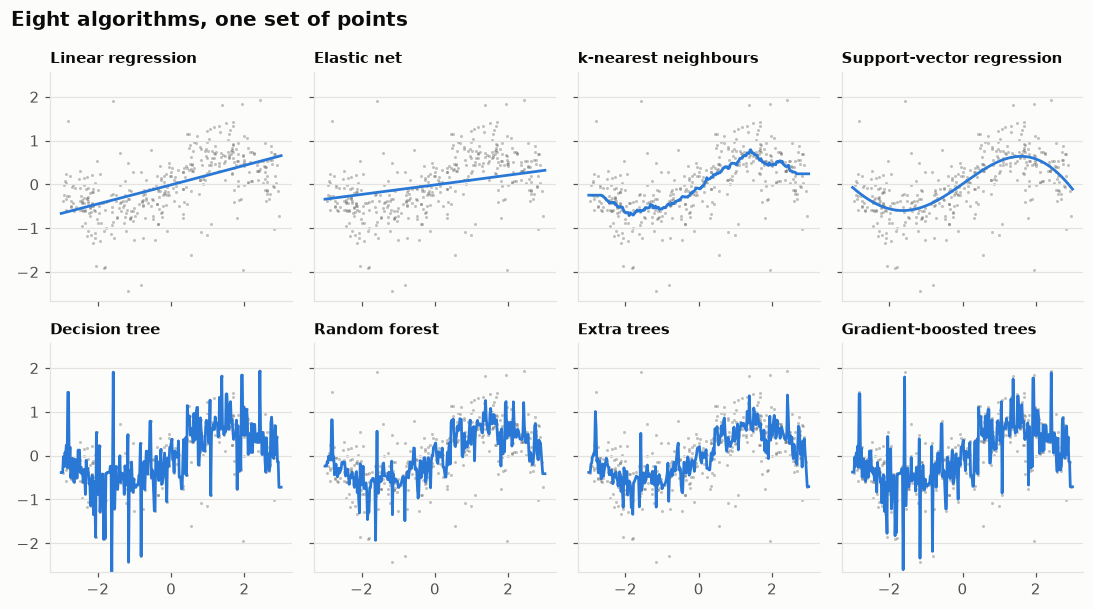

In [1]:
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import ml
from equity_research.research import model_choice as mc
from equity_research.research.backtest import decile_returns
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.indices import calendar_years, vendor_returns
from equity_research.research.strategy import TRAIN_FROM, StrategyConfig

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
charts.style()
LABELS = {name: c.label for name, c in mc.CANDIDATES.items()} | {mc.FALLBACK: "Ensemble of all eight"}

x, y = mc.toy_data()
grid = np.linspace(-3, 3, 301)
fig = charts.fit_panels(x, y, mc.toy_fits(x, y, grid), "Eight algorithms, one set of points", labels=LABELS)

What the panels show:

* **Linear regression** and the **elastic net** draw straight lines: they miss the wave (bias), but would draw almost
  the same line through another sample. The elastic net's line is flatter - shrunk towards the average.
* **k-nearest neighbours** follows the wave with a moving average of 40 neighbours; it flattens at the edges, where
  the neighbours all lie on one side.
* **SVR** draws a smooth curve and is barely moved by the outliers (errors beyond the tube cost linearly).
* The **decision tree** of depth 20 is a staircase that jumps to chase single points: it has memorised the sample.
* The **random forest** averages away much of that jumpiness; **extra trees** are smoother still.
* **Gradient boosting** with depth-10 trees is almost as jumpy as the single tree: each deep tree fits the residual
  noise left by the ones before it.

On real returns, where the noise is far larger, the models that chase points are the ones most at risk.

## Step 1 - the protocol, fixed before any result

Everything that could be tuned is fixed here, before a single prediction on our data has been seen, and written into
the configuration of every registered run (`model_choice.PROTOCOL`):

* **Candidates**: the book's eight models with exactly the settings its chapter 6 trains them with - the book's
  tuning is accepted as it is, and nothing is tuned again on our data.
* **Yardstick**: the **rank information coefficient (IC)**. Each month, the predictions of all index members are
  ranked, the year-ahead returns that followed are ranked, and the two rankings are correlated (Spearman's
  correlation). An IC of 1 would be a perfect ranking, 0 none; for stock returns an average of 0.02-0.05 is already
  valuable, because it is earned across hundreds of stocks at once (Grinold's *fundamental law of active management*:
  information ratio $\approx$ IC $\times\sqrt{\text{breadth}}$). The IC uses the whole cross-section of about 1,500
  companies, which makes it far less noisy than the return of a 7- or 10-stock portfolio, and it measures exactly what
  a ranking strategy needs: the order, not the size, of the predictions.
* **Choice rule**: each January, the candidate with the highest average IC over all months whose year-ahead return
  was *already known* that day (an expanding window) is used for the coming year. A month's IC is known only once
  its year has ended, so the choice in January 2015 rests on the months up to December 2013.
* **Fallback**: while fewer than 12 such months exist (2010 only), there is nothing to choose by, so the score is the
  average of all eight models' rankings - an **ensemble**.
* **Portfolio**: notebook 3.4's "value alone" portfolio - the top 30 % of the S&P 1500 by score, held until it leaves
  the top 40 %, weighted by market value, rebalanced monthly, 2010-2024, with costs.
* **Trials**: the eight single-model portfolios, the walk-forward choice and the ensemble - ten runs - are registered
  in one new family, `ml_model_choice_lo`, so the deflated Sharpe ratio of each counts all ten.

In [2]:
candidates = pd.DataFrame(
    {
        name: {
            "model": c.label,
            "scikit-learn": c.estimator,
            "settings": dict(c.settings) or "-",
            "power transform": c.power,
            "rows per fit": c.sample or "all",
        }
        for name, c in mc.CANDIDATES.items()
    }
).T
display(candidates)
display(pd.Series({k: v for k, v in mc.PROTOCOL.items() if k != "candidates"}, name="rule").to_frame())

,model,scikit-learn,settings,power transform,rows per fit
linear,Linear regression,LinearRegression,-,True,all
elastic_net,Elastic net,ElasticNet,{'l1_ratio': 1e-05},True,all
knn,k-nearest neighbours,KNeighborsRegressor,{'n_neighbors': 40},True,all
svr,Support-vector regression,SVR,"{'kernel': 'rbf', 'C': 100.0, 'gamma': 0.1, 'e...",True,10000
decision_tree,Decision tree,DecisionTreeRegressor,"{'max_depth': 20, 'random_state': 42}",False,all
random_forest,Random forest,RandomForestRegressor,"{'max_depth': 10, 'random_state': 42}",False,all
extra_trees,Extra trees,ExtraTreesRegressor,"{'max_depth': 10, 'random_state': 42}",False,all
gradient_boosting,Gradient-boosted trees,GradientBoostingRegressor,"{'n_estimators': 100, 'learning_rate': 0.1, 'm...",False,all


,rule
features,"ml.BOOK_CLIPS, clipped; missing -> training me..."
target,total return over the year after each month end
training,"walk-forward, refitted each January, quarter e..."
criterion,"mean monthly rank IC over members, out of sample"
choice,each January the highest mean IC so far; ensem...
distress,Altman Z'' <= 2.0 ranks last


## Step 2 - every candidate's walk-forward predictions

The universe is the S&P 1500, point-in-time, from 2006 (training) to 2024. Each candidate is refitted 16 times (each
January 2009-2024). The predictions are stored on disk under the data folder, keyed by the candidate's settings and a
digest of the data; the first run takes about 40 minutes (the book's exact gradient boosting takes two minutes a fit,
SVR one), later runs read them back.

In [3]:
cache = ResearchCache()
START, END = "2010-01-01", "2024-12-31"
data = load_universe_data(cache, "SP1500", TRAIN_FROM, END)
features = ml.book_features(data.ratios)
target = ml.forward_returns(data.returns, data.rebalances)
predictions = mc.candidate_predictions(
    features,
    target,
    data.members,
    data.rebalances,
    progress=lambda name, seconds, stored: print(
        f"{name:18s} {'read back' if stored else 'fitted'} in {seconds:,.0f} s"
    ),
)

left out 887 facts of 2 companies in ['GBP']


linear             fitted in 74 s


elastic_net        fitted in 79 s


knn                fitted in 109 s


svr                fitted in 1,551 s


decision_tree      fitted in 22 s


random_forest      fitted in 188 s


extra_trees        fitted in 21 s


gradient_boosting  fitted in 1,150 s


## Step 3 - how well each model ranked companies, out of sample

Every IC below is out of sample: the prediction for a month comes from a model fitted in the January before, on data
that ended a year before that. The ICs run from January 2009 (the first model) to December 2023 (the last month whose
year-ahead return has ended within the data).

Neighbouring months' ICs are not independent: the year-ahead returns of January and February share eleven months.
The plain t-statistic of the mean IC, which treats 180 months as 180 independent observations, would overstate the
evidence by roughly $\sqrt{12}$. The **Newey-West** t-statistic (`t_nw`) estimates the standard error allowing for
that overlap (11 lags, Bartlett weights); above about 2 the mean IC is unlikely to be zero by chance.

,mean_ic,ic_sd,positive,t_nw,months
Gradient-boosted trees,+0.003,0.072,51%,+0.2,180
Decision tree,+0.003,0.039,52%,+0.5,180
Support-vector regression,-0.000,0.035,48%,-0.0,180
k-nearest neighbours,-0.000,0.051,51%,-0.0,180
Random forest,-0.007,0.095,44%,-0.4,180
Linear regression,-0.027,0.126,36%,-1.1,180
Extra trees,-0.027,0.106,39%,-1.4,180
Elastic net,-0.028,0.124,36%,-1.2,180


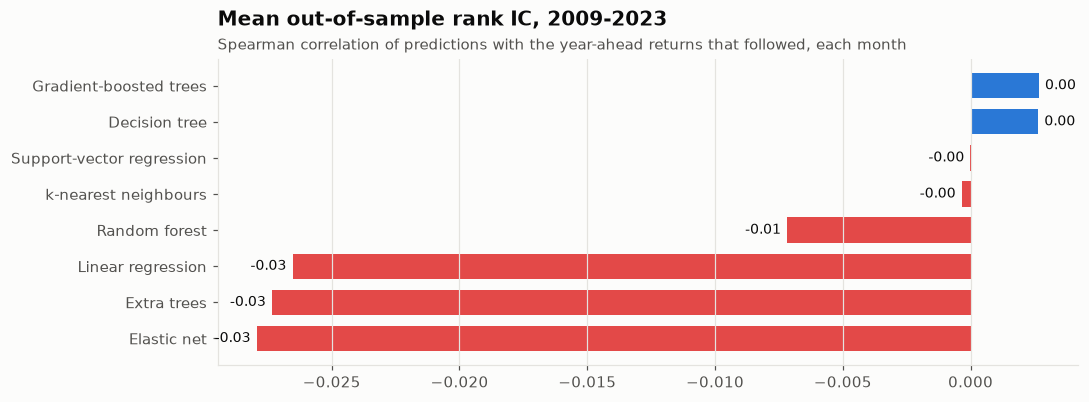

In [4]:
ic = mc.information_coefficients(predictions, target, data.members)
summary = mc.ic_summary(ic).rename(index=LABELS).sort_values("mean_ic", ascending=False)
display(
    summary.style.format(
        {"mean_ic": "{:+.3f}", "ic_sd": "{:.3f}", "positive": "{:.0%}", "t_nw": "{:+.1f}", "months": "{:.0f}"}
    )
)
fig = charts.ranked_bars(
    summary["mean_ic"],
    "Mean out-of-sample rank IC, 2009-2023",
    subtitle="Spearman correlation of predictions with the year-ahead returns that followed, each month",
)

In [5]:
yearly = ic.groupby(ic.index.year).mean().rename(columns=LABELS)
print("Mean rank IC by the year of the decision date")
display(yearly.style.format("{:+.3f}", na_rep="").background_gradient(cmap="RdYlGn", vmin=-0.15, vmax=0.15, axis=None))

Mean rank IC by the year of the decision date


,Linear regression,Elastic net,k-nearest neighbours,Support-vector regression,Decision tree,Random forest,Extra trees,Gradient-boosted trees
2006,,,,,,,,
2007,,,,,,,,
2008,,,,,,,,
2009,-0.126,-0.116,-0.099,+0.002,-0.047,-0.081,-0.067,-0.063
2010,+0.024,+0.037,+0.013,-0.007,+0.043,+0.055,+0.073,+0.041
2011,-0.033,-0.032,-0.030,-0.027,-0.007,-0.059,-0.069,-0.041
2012,+0.070,+0.094,+0.007,+0.030,+0.009,+0.023,+0.004,+0.021
2013,+0.036,+0.034,+0.023,-0.008,-0.013,+0.003,+0.038,+0.026
2014,-0.074,-0.075,-0.027,-0.037,-0.010,-0.078,-0.145,-0.058
2015,-0.084,-0.080,-0.018,-0.016,-0.005,-0.079,-0.082,-0.024


## Step 4 - the choice, made each January from what was known

Each row is a January. The columns show each candidate's average IC over the months known that day, the number of
months it rests on, and the model chosen for the year. Compare the choice with the "hindsight winner" - the model with
the best average IC over the whole period, which is what a contest judged on all the data would pick, and what could
not have been known in 2010.

In [6]:
dates = data.rebalances[data.rebalances >= pd.Timestamp(START)]
table = mc.selection_table(ic, dates)
shown = table.rename(columns=LABELS).assign(chosen=table["chosen"].map(LABELS))
display(shown.style.format({LABELS[n]: "{:+.3f}" for n in mc.CANDIDATES}, na_rep=""))
hindsight = summary.index[0]
print(f"Hindsight winner over 2009-2023: {hindsight}")
print("Years each model was chosen:", shown["chosen"].value_counts().to_dict())

,Linear regression,Elastic net,k-nearest neighbours,Support-vector regression,Decision tree,Random forest,Extra trees,Gradient-boosted trees,dates,chosen
year,,,,,,,,,,
2010,,,,,,,,,0,Ensemble of all eight
2011,-0.118,-0.110,-0.093,+0.001,-0.041,-0.071,-0.057,-0.055,13,Support-vector regression
2012,-0.051,-0.039,-0.043,-0.003,-0.002,-0.013,+0.003,-0.011,24,Extra trees
2013,-0.045,-0.037,-0.039,-0.011,-0.004,-0.028,-0.021,-0.021,36,Decision tree
2014,-0.016,-0.004,-0.027,-0.001,-0.000,-0.016,-0.015,-0.010,48,Decision tree
2015,-0.006,+0.003,-0.017,-0.002,-0.003,-0.012,-0.004,-0.003,60,Elastic net
2016,-0.017,-0.010,-0.019,-0.008,-0.004,-0.023,-0.028,-0.012,72,Decision tree
2017,-0.024,-0.018,-0.017,-0.008,-0.003,-0.028,-0.033,-0.012,85,Decision tree
2018,-0.023,-0.020,-0.014,-0.006,-0.000,-0.020,-0.031,-0.004,96,Decision tree


Hindsight winner over 2009-2023: Gradient-boosted trees
Years each model was chosen: {'Decision tree': 9, 'Gradient-boosted trees': 2, 'Support-vector regression': 1, 'Ensemble of all eight': 1, 'Extra trees': 1, 'Elastic net': 1}


### Does the choice pick well?

The choice is only useful if the model that has ranked best so far keeps ranking best. Below: the IC each year of
the model chosen that January, against the average of the eight and against the ensemble's own IC. (The ensemble's
IC is computed from its averaged ranks, like any other score's.)

In [7]:
members_on = data.members.reindex(data.rebalances)
pooled = mc.ensemble(predictions, data.members)
chosen = mc.chosen_score(predictions, table["chosen"], data.members)
ic_extra = pd.DataFrame(
    {
        "walk-forward choice": mc.rank_ic(chosen, target, data.members),
        "ensemble": mc.rank_ic(pooled, target, data.members),
    }
)
by_year = pd.concat([ic_extra, ic.mean(axis=1).rename("average of the eight")], axis=1)
by_year = by_year[by_year.index >= pd.Timestamp(START)].groupby(lambda d: d.year).mean()
display(by_year.T.style.format("{:+.3f}", na_rep=""))
display(
    pd.DataFrame(
        {
            "mean IC 2010-2023": by_year.mean(),
            "t_nw": [mc.newey_west_t(ic_extra.loc[START:, c]) for c in ic_extra]
            + [mc.newey_west_t(ic.mean(axis=1).loc[START:])],
        }
    ).style.format({"mean IC 2010-2023": "{:+.3f}", "t_nw": "{:+.1f}"})
)

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
walk-forward choice,+0.053,-0.027,+0.004,-0.013,-0.010,-0.080,+0.030,+0.018,+0.012,-0.026,+0.042,-0.024,-0.013,+0.020,
ensemble,+0.053,-0.051,+0.048,+0.028,-0.098,-0.074,+0.034,+0.009,-0.098,-0.108,+0.228,-0.093,+0.011,-0.001,
average of the eight,+0.035,-0.037,+0.032,+0.017,-0.063,-0.049,+0.020,+0.005,-0.061,-0.069,+0.147,-0.059,+0.001,-0.003,


,mean IC 2010-2023,t_nw
walk-forward choice,-0.001,-0.1
ensemble,-0.008,-0.4
average of the eight,-0.006,-0.4


## Step 5 - deciles: where the ranking pays

Each month every score sorts the members into ten groups; the table shows each group's equal-weighted return over the
next month in excess of the average member, a year, from 2010 (before costs; Altman distress cases rank last). A
long-only portfolio can only use the top decile, so a score whose skill is in spotting losers (the bottom) helps it
less.

In [8]:
scores = {name: ml.distress_last(p, data.ratios) for name, p in predictions.items()}
scores["walk-forward choice"] = ml.distress_last(chosen, data.ratios)
scores[mc.FALLBACK] = ml.distress_last(pooled, data.ratios)
after = data.rebalances >= pd.Timestamp(START)
deciles = {LABELS.get(n, n): decile_returns(s.loc[after], data.returns, data.members) for n, s in scores.items()}
excess = pd.DataFrame({n: d["excess"] for n, d in deciles.items()}).T
excess["top t"] = [d.loc[10, "t"] for d in deciles.values()]
display(excess.style.format("{:+.1%}").format("{:+.1f}", subset=["top t"]))

decile,1,2,3,4,5,6,7,8,9,10,top t
Linear regression,-0.9%,+0.6%,-0.6%,-1.5%,-0.9%,-0.7%,-0.0%,+1.5%,+0.6%,+1.9%,+0.6
Elastic net,+0.3%,-1.0%,-0.3%,-1.2%,-1.8%,+0.2%,+1.5%,+0.5%,+0.2%,+1.7%,+0.6
k-nearest neighbours,-0.2%,-0.9%,-0.5%,-0.5%,+0.3%,-0.5%,-1.2%,-0.3%,+0.8%,+3.1%,+1.8
Support-vector regression,+2.0%,-0.1%,-1.2%,-0.2%,-0.8%,-0.0%,-1.4%,+0.2%,+0.6%,+1.0%,+0.7
Decision tree,+0.3%,+0.1%,-1.1%,-1.0%,+1.0%,-1.1%,-0.7%,+0.7%,+0.2%,+1.7%,+1.0
Random forest,+0.2%,-1.4%,-0.7%,+0.2%,+0.3%,-1.8%,-0.0%,+0.1%,+1.4%,+1.8%,+0.6
Extra trees,-0.6%,-0.6%,-0.0%,-0.9%,-0.8%,-0.1%,+0.2%,-0.0%,+1.0%,+1.8%,+0.7
Gradient-boosted trees,+0.4%,-0.7%,-0.9%,-1.2%,-0.1%,-0.8%,-0.2%,+1.3%,+1.0%,+1.2%,+0.5
walk-forward choice,+0.5%,-0.2%,+0.0%,-0.7%,+0.7%,-1.1%,-1.3%,+0.1%,+0.8%,+1.4%,+0.7
Ensemble of all eight,-0.9%,-1.7%,-0.6%,-0.3%,+0.5%,-1.2%,+0.1%,+2.0%,+0.6%,+1.4%,+0.6


## Step 6 - the portfolios, every one registered

Each score runs in the same portfolio (notebook 3.4's "value alone"), and every run is registered in the family
`ml_model_choice_lo`. The *deflated active Sharpe ratio* is the probability that the run's information ratio beats
what the luckiest of all the family's trials would show by chance; 95 % would count as evidence.

In [9]:
# the registry is the shared database: connected here, just before the runs, because a serverless database
# pauses when idle and is woken by the first connection
engine = get_engine()
base = StrategyConfig(
    family=mc.FAMILY,
    universe="SP1500",
    start=START,
    end=END,
    enter=0.30,
    exit_=0.40,
    long_only=True,
    beta_neutral=False,
    weighting="market_cap",
)
runs = {}
for name, score in scores.items():
    config = replace(base, factors=((f"ml:{name}", 1.0),))
    runs[LABELS.get(name, name)] = mc.run_score(data, config, score, protocol=mc.PROTOCOL, engine=engine)
sptm = vendor_returns(cache, "SPTM", total=True)
COLUMNS = {
    "cagr": "{:.1%}",
    "vol": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
metrics = pd.DataFrame({name: r.metrics for name, r in runs.items()}).T
display(metrics[list(COLUMNS)].sort_values("information_ratio", ascending=False).style.format(COLUMNS))
print("Registered as research runs", {name: r.run_id for name, r in runs.items()})
print("Trials in the family:", int(metrics["trials"].max()))

,cagr,vol,sharpe,max_drawdown,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
k-nearest neighbours,14.7%,18.3%,0.84,-33%,+0.6%,2.9%,+0.26,28%,2.9
Decision tree,14.5%,18.9%,0.81,-39%,+0.4%,3.5%,+0.17,17%,4.4
Support-vector regression,14.2%,17.9%,0.84,-33%,+0.2%,3.3%,+0.08,10%,3.0
Random forest,14.0%,18.8%,0.79,-33%,+0.0%,4.2%,+0.06,9%,2.4
Ensemble of all eight,13.7%,18.7%,0.78,-34%,-0.3%,4.7%,-0.01,6%,2.6
Gradient-boosted trees,13.7%,18.6%,0.78,-33%,-0.2%,3.5%,-0.01,5%,4.2
Linear regression,13.2%,18.6%,0.76,-44%,-0.7%,6.6%,-0.05,4%,1.5
Elastic net,12.6%,18.6%,0.73,-42%,-1.2%,6.4%,-0.15,2%,1.4
walk-forward choice,13.2%,18.8%,0.76,-39%,-0.7%,3.3%,-0.15,2%,3.8
Extra trees,12.7%,18.2%,0.75,-32%,-1.2%,4.0%,-0.25,1%,2.0


Registered as research runs {'Linear regression': 130, 'Elastic net': 131, 'k-nearest neighbours': 132, 'Support-vector regression': 133, 'Decision tree': 134, 'Random forest': 135, 'Extra trees': 136, 'Gradient-boosted trees': 137, 'walk-forward choice': 138, 'Ensemble of all eight': 139}
Trials in the family: 10


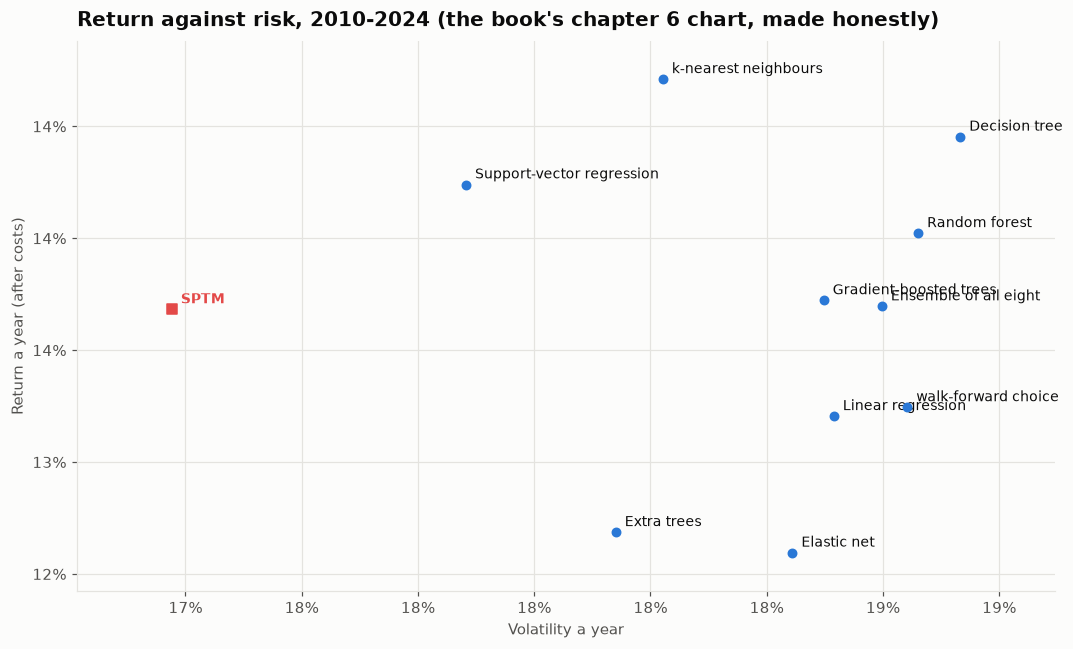

In [10]:
spread = metrics[["vol", "cagr"]].rename(columns={"vol": "x", "cagr": "y"})
spread.loc["SPTM"] = [
    float(sptm.loc[START:END].std() * np.sqrt(252)),
    float((1 + sptm.loc[START:END]).prod() ** (252 / len(sptm.loc[START:END])) - 1),
]
fig = charts.labeled_scatter(
    spread,
    "Return against risk, 2010-2024 (the book's chapter 6 chart, made honestly)",
    xlabel="Volatility a year",
    ylabel="Return a year (after costs)",
    highlight="SPTM",
)

Each year: the portfolio's return minus SPTM's


trade_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
walk-forward choice,-0.5%,+0.5%,-2.7%,-0.5%,-1.1%,-5.2%,+3.2%,+1.6%,+0.4%,-0.2%,+2.6%,+8.2%,-6.7%,+3.2%,-9.0%
Ensemble of all eight,-0.5%,+3.4%,-0.0%,+1.3%,-3.8%,-1.2%,+7.3%,+3.9%,-4.0%,+0.3%,+4.7%,+6.8%,-1.2%,-7.0%,-12.3%
Gradient-boosted trees,-0.0%,+1.4%,+2.2%,-0.6%,-2.4%,-2.4%,+3.4%,-0.1%,-3.9%,+6.2%,+4.9%,-3.0%,-7.0%,+3.2%,-0.7%


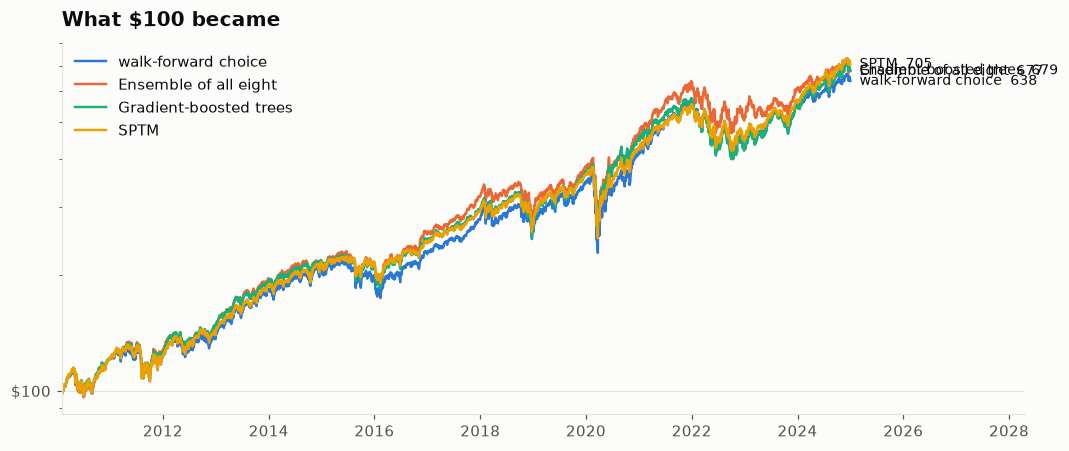

In [11]:
shown_runs = {
    k: runs[k].backtest.net for k in ("walk-forward choice", "Ensemble of all eight", "Gradient-boosted trees")
}
fig = charts.growth(shown_runs | {"SPTM": sptm}, "What $100 became")
ahead = pd.DataFrame(
    {
        name: calendar_years({name: r, "SPTM": sptm}).pipe(lambda t, n=name: t[n] - t["SPTM"])
        for name, r in shown_runs.items()
    }
)
print("Each year: the portfolio's return minus SPTM's")
display(ahead.T.style.format("{:+.1%}", na_rep=""))

## Findings

**In short: chosen honestly, none of the book's eight algorithms predicts which S&P 1500 stocks will do better
over the next year, so there is no right algorithm to pick.** The book's finding that gradient-boosted trees beat
the market came from how it chose, not from what the model learned.

**1. No algorithm ranks stocks better than chance (step 3).** Over the 180 month-ends from 2009 to 2023, the best mean
rank IC is +0.003, shared by gradient-boosted trees (Newey-West t +0.2) and the decision tree (t +0.5). A t-statistic
has to pass about 2 to count as evidence, so these are indistinguishable from zero. Linear regression, elastic net and
extra trees are slightly *negative* (-0.027, -0.028 and -0.027; t -1.1, -1.2 and -1.4). These are not reliable
either: they come from a few violent years. Linear regression's IC was -0.163 for decisions made in 2018, -0.184 in
2019 (the year-ahead returns ran into value's collapse in 2020) and +0.252 in 2020 (into the 2021 rebound). The linear
models bet hardest on cheapness, so they swing the most (IC standard deviation 0.126, against 0.035 to 0.051 for SVR,
the decision tree and KNN).

**2. The walk-forward choice picked noise, and did no better than its candidates (step 4).** From 2014 the leader's running
mean IC is never above +0.005, and the leaders are separated by a few thousandths. Each January's "best so far" is
therefore the least-bad candidate, by a margin far smaller than sampling error. The rule chose the
decision tree in 9 of the 15 years, gradient-boosted trees in 2 (2022 and 2023), and SVR, extra trees and elastic net
once each; the ensemble filled 2010, before any IC was known. The chosen score's IC over 2010-2023 is -0.001 (t
-0.1), the ensemble's -0.008 (t -0.4). The hindsight winner, gradient-boosted trees, was chosen in only two years: the
rule could not have found it in time, because its lead appeared only late and is too small to matter.

**3. Every top decile beats the average member, and none convincingly (step 5).** A long-only portfolio buys from the
top. There, every score's top decile earned between +1.0 % and +3.1 % a year more than the average member (before
costs). The highest is KNN's +3.1 % (t 1.8), and no t-statistic reaches 2. The ten groups do not line up in order:
SVR's *bottom* decile earned +2.0 %, more than its top (+1.0 %). (Distressed companies rank last in every score, so
none of them reaches a top decile.)

**4. In the portfolio, every learner ends close to the market (step 6).** SPTM returned 13.7 % a year from 2010 to
2024, with 17.2 % volatility and a worst fall of 35 %. The ten portfolios returned between 12.6 % (elastic net) and
14.7 % (KNN), all with more volatility (17.9 % to 18.9 %). The best information ratio is KNN's +0.26 (+0.6 % a year
active, 2.9 % tracking error). Its deflated active Sharpe ratio is 28 %, far below the 95 % that would count as
evidence: once the ten trials are allowed for, it is consistent with being the luckiest of ten scores without skill.
KNN's IC was -0.000, and the rule never chose it. Picking it now from this table would repeat the book's hindsight
choice. The two pre-registered combinations did no better:

| | return a year | active | information ratio | deflated active Sharpe | turnover |
|---|---|---|---|---|---|
| walk-forward choice | 13.2 % | -0.7 % | -0.15 | 2 % | 3.8 |
| ensemble of all eight | 13.7 % | -0.3 % | -0.01 | 6 % | 2.6 |
| gradient-boosted trees (the book's pick) | 13.7 % | -0.2 % | -0.01 | 5 % | 4.2 |

Switching models costs something too: the walk-forward choice turned its portfolio over 3.8 times a year, against
2.6 for the ensemble, which changes only gradually.

**5. Against the book and against notebook 3.4.** The book reported gradient-boosted trees growing money 3.95-fold
over 2010-2020 against the S&P 500's 3.51-fold. Trained only on years already over and placed in a real portfolio, the
same model with the book's settings (100 trees, depth 10) returned 13.7 % a year, the same as SPTM. Notebook 3.4's
faster histogram version (31 leaves), in the same portfolio, returned 13.5 % with an information ratio of -0.06. The
two implementations give the same answer, so 3.4's shortcut does not change its conclusion.

**6. A result this weak moves with trivia.** The database returns rows in no fixed order, and a decision tree breaks
ties between equally good splits by row order. Running the notebook twice on identical data first gave different tree
predictions: up to 0.80 apart in predicted return for the depth-20 decision tree, and 0.23 for gradient-boosted
trees. Before the inputs were sorted, an earlier execution (research runs 120-129, the same configurations) had
the decision tree at 14.5 % a year (information ratio +0.19) against 14.4 % (+0.17) here. Gradient-boosted trees were
at 13.5 % (-0.04) against 13.7 % (-0.01), and the walk-forward choice picked the decision tree in 6 years and
gradient-boosted trees in 4, against 9 and 2 here. Some values also differ in their last decimal places from one load to the next (about 1e-16, from sums added in
another order), and the depth-10 boosted trees turn even that into predictions up to 0.28 apart. The inputs are now
sorted and rounded to seven significant digits before fitting, so a fresh load gives the same fits. The registered
runs 130-139 come from before that rounding: their gradient-boosted trees are one of the slightly different fits a
load could give.
Even so, when reordering the rows changes a model's ranking, the ranking was never evidence.

**What this means.** The protocol did its job: it decided before the results which model would be used and how
success would be measured, and it reports the outcome even though nothing won. On these 18 accounting ratios the book's
algorithms find no reliable signal for the following year's return. A more flexible learner cannot extract a signal
that is not in the features. If a learned score is used at all, the pre-registered answer is the ensemble: it trades
less than the yearly choice or the book's pick, it does not depend on a noisy yearly choice, and it did as well as the book's pick and better than
the yearly choice. Tuning the
models further on these results would be the multiple testing this notebook set out to avoid. A real improvement would
need new information, such as the analysts' estimates (I/B/E/S) or price momentum, tested as a new pre-registered
family.

The ten portfolios are research runs 130-139 in the family `ml_model_choice_lo`, each counted against all ten trials.


## Glossary

* **Supervised learning** - fitting a model that maps inputs (*features*) to a known outcome (the *target*) from
  examples, instead of writing the rule by hand.
* **Bias / variance** - a model's error from being too rigid to capture the true relation (bias), and from fitting the
  accidents of its particular training sample (variance); **overfitting** is the second.
* **Hyperparameter** - a setting chosen before fitting (tree depth, $k$, $C$), as opposed to the parameters the fit
  itself estimates; tuning it on the data you will judge by is a form of selection bias.
* **Walk-forward (expanding-window) validation** - training only on data available before each prediction date, the
  window growing as time passes.
* **Look-ahead bias** - using information in a backtest that was not available at the decision date.
* **Selection bias / multiple testing** - the best of many trials looks better than its true skill because it is
  partly the luckiest; the **deflated Sharpe ratio** (Bailey and Lopez de Prado, 2014) is the probability that a Sharpe
  ratio beats what the best of the trials would reach by luck.
* **Pre-registration** - writing down the candidates, the yardstick and the decision rule before seeing results, so
  the result cannot shape the method.
* **Rank information coefficient (IC)** - the Spearman correlation, across stocks on one date, between a score and the
  returns that followed.
* **Newey-West standard error** - a standard error of a mean that allows for correlation between neighbouring
  observations (here, overlapping year-ahead returns).
* **Ensemble** - a prediction formed by combining several models (here, averaging their rankings); it needs no choice
  among them.
* **Altman Z''** - Altman's (1995) bankruptcy-prediction score for non-manufacturers, a weighted sum of four
  balance-sheet ratios; 2 or less is the distress zone.
* **Active return, tracking error, information ratio** - the portfolio's return over the benchmark's, the volatility
  of that difference, and their ratio (see notebook 3.2).